# Does adding soil change temperatures inside the snowpack?
PPSA · TRAM · HEEN — the six lapse-rate forcing pairs, **base versus soil**, with existing simulations only. Three concise figures and a six-row meeting table compare snow layer temperatures. These are modeled sensitivity experiments, without matched snow-temperature observations.

The base configuration prescribes TSG = 273.15 K and disables `SNP_SOIL`/`SOIL_FLUX`; the soil run replaces that treatment with the 28-layer, 5 m idealized loam column and an upward 0.06 W m⁻² deep flux. Differences include the changed boundary treatment, water storage and evolving snow geometry; this is not a controlled test of heat capacity alone. Both members of a pair use the same meteorological forcing.

Analysis figures display inline and are not saved automatically. Diagnostic tables, caches, and copied inputs go to the ignored `temporary/` folder. Export only explicitly selected final figures to `figures/`.


In [1]:
from pathlib import Path
import os, sys, ast, json, configparser
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
HERE=Path.cwd()
while not (HERE/'sites').is_dir():
    if HERE==HERE.parent:raise RuntimeError('Run from snow_modeling_point')
    HERE=HERE.parent
ROOT=HERE;sys.path.insert(0,str(ROOT/'sites/all_sites'))
from _thermal_diagnostics import snow_profiles, PROFILE_EDGES
MODEL=Path(os.environ.get('SNOWPACK_SITES','/home/cassie/python/models/run_snowpack/sites'))
OUT=ROOT/'temporary/internal_snow_temperature';OUT.mkdir(parents=True,exist_ok=True)
CACHE=OUT/'cache';CACHE.mkdir(exist_ok=True);(CACHE/'.gitignore').write_text('*\n!.gitignore\n')
REF=ROOT/'sites/all_sites/5_read_snowpack_output_compare_all_sites_lapserate_soil_figure.ipynb'
ref=json.loads(REF.read_text())
wanted={'SITE_CONFIG','FORCINGS','COLORS','LABELS','SNOW_FREE_CM','SWE_FREE_KG_M2','SNOW_FREE_DAYS','MIN_VALID_HOURS_PER_DAY','MIN_SEASON_PEAK_CM'}
for cell in ref['cells']:
    if cell['cell_type']!='code':continue
    for node in ast.parse(''.join(cell['source'])).body:
        if isinstance(node,ast.Assign) and any(isinstance(t,ast.Name) and t.id in wanted for t in node.targets):exec(compile(ast.Module(body=[node],type_ignores=[]),str(REF),'exec'))
        elif isinstance(node,ast.FunctionDef) and node.name=='melt_out':exec(compile(ast.Module(body=[node],type_ignores=[]),str(REF),'exec'))
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110})
def csv(df,name):df.to_csv(OUT/f'{name}.csv',index=False)
def read_smet(path):
    h={}
    with path.open() as f:
        for line in f:
            if line.strip()=='[DATA]':break
            if '=' in line and not line.lstrip().startswith('#'):
                k,v=line.split('=',1);h[k.strip()]=v.strip()
        d=pd.read_csv(f,sep=r'\s+',names=h['fields'].split())
    d.index=pd.DatetimeIndex(pd.to_datetime(d.pop('timestamp')),name='time');d=d.replace(float(h['nodata']),np.nan)
    assert float(h['tz'])==0 and d.index.is_unique and d.index.is_monotonic_increasing
    for field in d:
        j=h['fields'].split().index(field)
        d[field]=d[field]*float(h['units_multiplier'].split()[j])+float(h['units_offset'].split()[j])
        if h['plot_unit'].split()[j]=='K':d[field]-=273.15
    d['HS_cm']=100*d.HS_mod
    return h,d
runs={};audit=[];paired={};selected={};seasons=[];fractions=[f'fraction_{i:02}' for i in range(40)]


## Paired sampling and coordinates
PRO 0503 contains **element** temperatures in °C. The writer reports vertical coordinates; multiplying by cos(38°) gives distances normal to the slope. Soil elements are removed before computing snow statistics. At fixed **5, 10, 20 and 50 cm above ground**, adjacent snow-element midpoints are linearly interpolated, without extrapolating into soil or outside snow. A snow-depth threshold of 50 cm **vertically** in both runs makes the main comparisons about a substantial, simultaneous snow cover, rather than bare ground. Missing positions remain missing.

For each pair, daily means use **the same 18 or more valid hourly values**. Seasonal statistics are means of valid paired daily means, requiring ≥90% valid days in the subset with ≥18 simultaneous snow-covered hours. Coverage relative to all winter days is separately reported; warm low-snow days are not implicitly filled. Winter is December–February; spring is March–May. First simulated seasons are flagged and omitted from the meeting medians.

The normalized profiles divide each snowpack into 40 equal height fractions (0 = ground, 1 = snow surface), integrating native layer temperatures conservatively within each bin. Both runs use matching timestamps but their actual snow heights may differ; these are geometric positions, not tracked snow parcels. The bulk mean is snow-mass weighted. Cold energy deficit is the nonnegative sensible energy needed to bring subfreezing snow to 0°C, per m² of slope, excluding latent heat. Changes in total cold deficit also reflect different snow mass.

Field definitions follow the local output headers and [SNOWPACK 3.7.0 source](https://code.wsl.ch/snow-models/snowpack/-/tree/Snowpack-3.7.0/snowpack). The supporting parser uses the installed `Constants.h`; no effective heat capacity for phase change is included in the cold deficit.


In [2]:
for site,cfg in SITE_CONFIG.items():
    for f,prefix in FORCINGS.items():
        for experiment in ['base','soil']:
            stem=f'{prefix}_{site}_{cfg[f]}_{experiment}';path=MODEL/site/'output'/f'{stem}.smet'
            h,d=read_smet(path);cp=configparser.ConfigParser(interpolation=None,delimiters=('=',));cp.read(path.with_suffix('.ini'))
            n=28 if experiment=='soil' else 0
            cosine=np.cos(np.deg2rad(float(h['slope_angle'])))
            p=snow_profiles(path.with_suffix('.pro'),cosine,n,CACHE)
            p=p.reindex(d.index);p['HS_cm']=d.HS_cm;p['SWE']=d.SWE;p['Qg0']=d.Qg0;p['TSG']=d.TSG
            # Native snow ColdContent is MJ/m² of slope; check reconstruction conservatively.
            valid=(d.HS_cm>=50)&p.cold_deficit_MJm2.notna()
            discrepancy=(p.loc[valid,'cold_deficit_MJm2']+d.loc[valid,'ColdContentSnow']).abs()
            audit.append(dict(site=site,forcing=f,experiment=experiment,start=d.index.min(),end=d.index.max(),hours=len(d),
                SNP_SOIL=cp['SNOWPACK']['SNP_SOIL'],SOIL_FLUX=cp['SNOWPACK']['SOIL_FLUX'],GEO_HEAT=cp['SNOWPACK']['GEO_HEAT'],
                TSG_generator_C=0. if experiment=='base' else np.nan,pro_records=len(p),
                median_cold_content_check_abs_MJm2=discrepancy.median(),p99_cold_content_check_abs_MJm2=discrepancy.quantile(.99),
                file=str(path),profile=str(path.with_suffix('.pro'))))
            runs[site,f,experiment]=p
            print('Extracted',stem,len(p),'hours',flush=True)
        a=runs[site,f,'base'];b=runs[site,f,'soil'];idx=a.index.intersection(b.index)
        snow=(a.loc[idx,'HS_cm']>=50)&(b.loc[idx,'HS_cm']>=50)
        delta=b.loc[idx].drop(columns=[])-a.loc[idx]
        delta=delta.where(snow,axis=0)
        days=delta.resample('D').mean().where(delta.resample('D').count()>=18)
        days['paired_snow_hours']=snow.resample('D').sum()
        paired[site,f]=dict(base=a.loc[idx],soil=b.loc[idx],mask=snow,delta=delta,daily=days)
        days[['T_above_10cm_C','T_above_20cm_C','bulk_mass_T_C','cold_deficit_MJm2','HS_cm','paired_snow_hours']].to_csv(OUT/f'daily_soil_minus_base_{site}_{f}.csv',index_label='date_UTC')
        years=idx.year+(idx.month>=10);first=int(years.min())
        for wy in sorted(set(years)):
            season_a=a.loc[f'{wy-1}-10-01':f'{wy}-09-30'];season_b=b.loc[f'{wy-1}-10-01':f'{wy}-09-30']
            melt_a,status_a=melt_out(season_a.HS_cm,season_a.SWE);melt_b,status_b=melt_out(season_b.HS_cm,season_b.SWE)
            for period,start,end in [('winter',pd.Timestamp(wy-1,12,1),pd.Timestamp(wy,3,1)-pd.Timedelta(days=1)),('spring',pd.Timestamp(wy,3,1),pd.Timestamp(wy,5,31))]:
                q=days.reindex(pd.date_range(start,end));eligible=q.paired_snow_hours>=18
                row=dict(site=site,forcing=f,water_year=int(wy),period=period,first_season=int(wy)==first,eligible_days=int(eligible.sum()),expected_days=len(q),winter_snow_coverage=eligible.mean(),
                    melt_base=melt_a,melt_soil=melt_b,melt_base_status=status_a,melt_soil_status=status_b,
                    melt_shift_days=(melt_b-melt_a).days if pd.notna(melt_a) and pd.notna(melt_b) else np.nan)
                for field in ['T_above_10cm_C','T_above_20cm_C','bulk_mass_T_C','cold_deficit_MJm2','HS_cm']:
                    valid=q.loc[eligible,field].dropna();required=int(np.ceil(.9*eligible.sum()))
                    row['delta_'+field]=valid.mean() if len(valid)>=max(required,10) else np.nan
                    row['valid_days_'+field]=len(valid)
                seasons.append(row)
        print('Paired',site,f,flush=True)
audit=pd.DataFrame(audit);seasons=pd.DataFrame(seasons);csv(audit,'run_audit');csv(seasons,'seasonal_temperature_metrics')
assert len(audit)==12
assert audit.median_cold_content_check_abs_MJm2.max()<.03,'Check energy reconstruction/area convention'
display(audit[['site','forcing','experiment','hours','SNP_SOIL','SOIL_FLUX','median_cold_content_check_abs_MJm2']].round(4))


Extracted hrrrak_lapserate_ppsa_WY2020-WY2025_base 51884 hours


Extracted hrrrak_lapserate_ppsa_WY2020-WY2025_soil 51883 hours


Paired ppsa hrrr


Extracted met_hrrrak_lapserate_ppsa_WY2020-WY2025_base 51883 hours


Extracted met_hrrrak_lapserate_ppsa_WY2020-WY2025_soil 51883 hours


Paired ppsa mixed


... (9 outputs left out)

Extracted met_hrrrak_lapserate_heen_WY2020-WY2022_base 26280 hours


Extracted met_hrrrak_lapserate_heen_WY2020-WY2022_soil 26280 hours


Paired heen mixed


,site,forcing,experiment,hours,SNP_SOIL,SOIL_FLUX,median_cold_content_check_abs_MJm2
0,ppsa,hrrr,base,51884,false,false,0.0004
1,ppsa,hrrr,soil,51883,true,true,0.0004
2,ppsa,mixed,base,51883,false,false,0.0004
3,ppsa,mixed,soil,51883,true,true,0.0004
4,tram,hrrr,base,51884,false,false,0.0003
5,tram,hrrr,soil,51883,true,true,0.0003
6,tram,mixed,base,25579,false,false,0.0002
7,tram,mixed,soil,25579,true,true,0.0003
8,heen,hrrr,base,51883,false,false,0.0004
9,heen,hrrr,soil,51883,true,true,0.0004


## 1. A winter vertical profile at each site
Use the latest water year common to the two forcings with **at least 30 matched Jan–Feb snow-covered days** in each forcing, and ≥90% valid normalized-profile days among eligible days. Each curve first averages matching hours within each day, then weights days equally. Counts and actual mean snow depths are exported. A thin lower-layer temperature effect can be diluted in a whole-snowpack average.


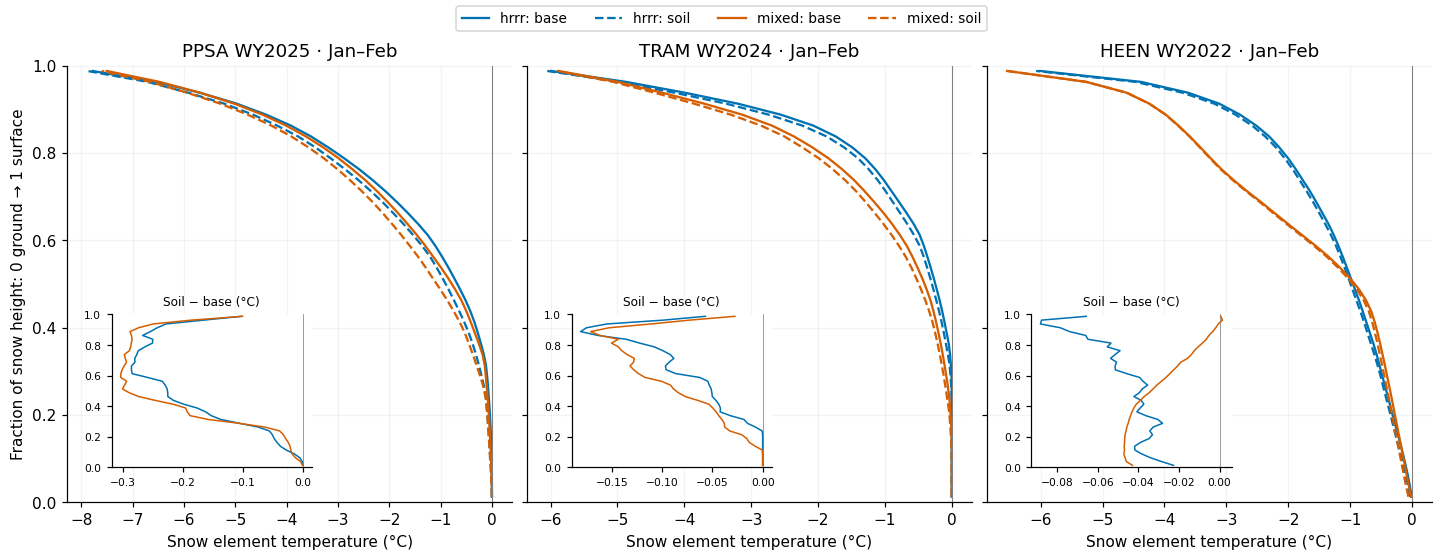

In [3]:
profile_rows=[];profile_curves={}
for site in SITE_CONFIG:
    candidates=sorted(set(seasons.query('site==@site and period=="winter"').water_year),reverse=True)
    for wy in candidates:
        ready=True;temp={}
        for f in FORCINGS:
            pair=paired[site,f];idx=pd.date_range(f'{wy}-01-01',pd.Timestamp(wy,3,1)-pd.Timedelta(hours=1),freq='h')
            mask=pair['mask'].reindex(idx,fill_value=False);aa=pair['base'].reindex(idx).loc[mask];bb=pair['soil'].reindex(idx).loc[mask]
            count=aa[fractions].resample('D').count().min(axis=1)
            da=aa[fractions].resample('D').mean().where(count>=18,axis=0);db=bb[fractions].resample('D').mean().where(count>=18,axis=0)
            joint=da.notna().all(axis=1)&db.notna().all(axis=1)
            eligible=int((mask.resample('D').sum()>=18).sum())
            if joint.sum()<30 or joint.sum()<.9*eligible:ready=False;break
            temp[f]=(da.loc[joint].mean(),db.loc[joint].mean(),int(joint.sum()),aa.HS_cm.mean(),bb.HS_cm.mean())
        if ready:selected[site]=int(wy);profile_curves[site]=temp;break
    assert site in selected,f'No complete common winter: {site}'
fig,axs=plt.subplots(1,3,figsize=(13,5),sharey=True,layout='constrained')
y=(PROFILE_EDGES[1:]+PROFILE_EDGES[:-1])/2
for ax,site in zip(axs,SITE_CONFIG):
    inset=ax.inset_axes([.10,.08,.45,.35]);inset.axvline(0,color='gray',lw=.5);inset.set(title='Soil − base (°C)',ylim=(0,1));inset.tick_params(labelsize=7);inset.title.set_fontsize(8)
    for f,(a,b,days,ha,hb) in profile_curves[site].items():
        ax.plot(a,y,color=COLORS[f],ls='-',label=f'{f}: base')
        ax.plot(b,y,color=COLORS[f],ls='--',label=f'{f}: soil');inset.plot(b.values-a.values,y,color=COLORS[f],lw=1)
        for fraction,ta,tb in zip(y,a,b):profile_rows.append(dict(site=site,forcing=f,water_year=selected[site],fraction_height=fraction,base_C=ta,soil_C=tb,soil_minus_base_C=tb-ta,paired_days=days,base_mean_HS_cm=ha,soil_mean_HS_cm=hb))
    ax.axvline(0,color='gray',lw=.7);ax.set(title=f'{site.upper()} WY{selected[site]} · Jan–Feb',xlabel='Snow element temperature (°C)',ylim=(0,1));ax.grid(alpha=.15)
axs[0].set_ylabel('Fraction of snow height: 0 ground → 1 surface');fig.legend(*axs[-1].get_legend_handles_labels(),loc='outside upper center',ncol=4,fontsize=9)
plt.show();csv(pd.DataFrame(profile_rows),'winter_normalized_profiles');csv(pd.DataFrame([dict(site=s,water_year=y) for s,y in selected.items()]),'selected_seasons')


## 2. How large is the seasonal temperature change?
Each point is a winter or spring **seasonal paired mean**; horizontal marks are medians after excluding the first simulated season. Positive values mean warmer snow with soil. Light crosses mark first seasons. No snow-free values enter the statistics. The full seasonal table retains valid-day counts and snow-coverage fractions.


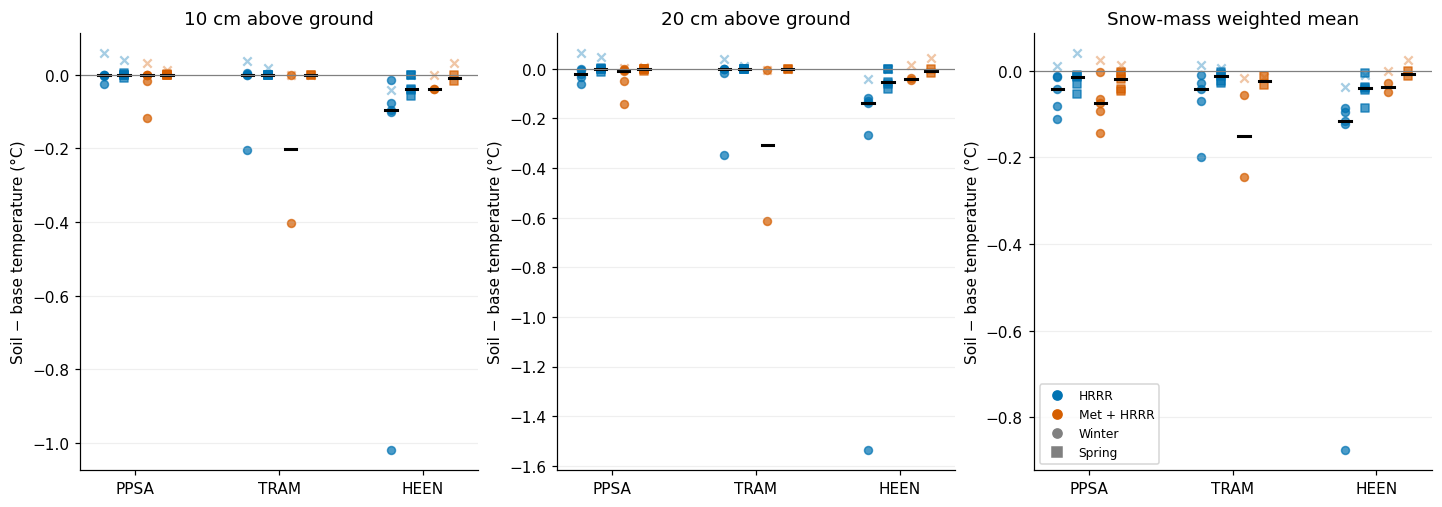

In [4]:
fig,axs=plt.subplots(1,3,figsize=(13,4.5),layout='constrained')
fields=['delta_T_above_10cm_C','delta_T_above_20cm_C','delta_bulk_mass_T_C']
for ax,field,title in zip(axs,fields,['10 cm above ground','20 cm above ground','Snow-mass weighted mean']):
    for i,site in enumerate(SITE_CONFIG):
        for j,f in enumerate(FORCINGS):
            for period,shift,marker in [('winter',-.07,'o'),('spring',.07,'s')]:
                a=seasons.query('site==@site and forcing==@f and period==@period');x=i+(j-.5)*.3+shift
                valid=a.loc[~a.first_season,field].dropna();first=a.loc[a.first_season,field].dropna()
                ax.scatter(np.full(len(valid),x),valid,color=COLORS[f],marker=marker,s=27,alpha=.7)
                ax.scatter(np.full(len(first),x),first,color=COLORS[f],marker='x',s=30,alpha=.35)
                if len(valid):ax.plot([x-.04,x+.04],[valid.median()]*2,color='black',lw=2)
    ax.axhline(0,color='gray',lw=.8);ax.set(title=title,ylabel='Soil − base temperature (°C)',xticks=range(3),xticklabels=[s.upper() for s in SITE_CONFIG]);ax.grid(axis='y',alpha=.2)
axs[-1].plot([],[],color=COLORS['hrrr'],marker='o',ls='',label='HRRR');axs[-1].plot([],[],color=COLORS['mixed'],marker='o',ls='',label='Met + HRRR')
axs[-1].plot([],[],color='gray',marker='o',ls='',label='Winter');axs[-1].plot([],[],color='gray',marker='s',ls='',label='Spring');axs[-1].legend(fontsize=8)
plt.show()


## 3. Spring context: lower snow temperature, interface heat and snow disappearance
Same water years as the winter figure. Both runs are plotted on common calendar dates from 45 days before the earliest to 7 days after the latest melt-out shown. Lower snow temperatures are shown only where that run has ≥50 cm vertical snow depth and ≥18 valid hours/day. Upward interface flux can warm snow; differences in snow depth and disappearance are displayed separately. Vertical lines indicate modeled base (solid) and soil (dashed) melt-out. This is context for the temperature response, not a causal flux–temperature regression.


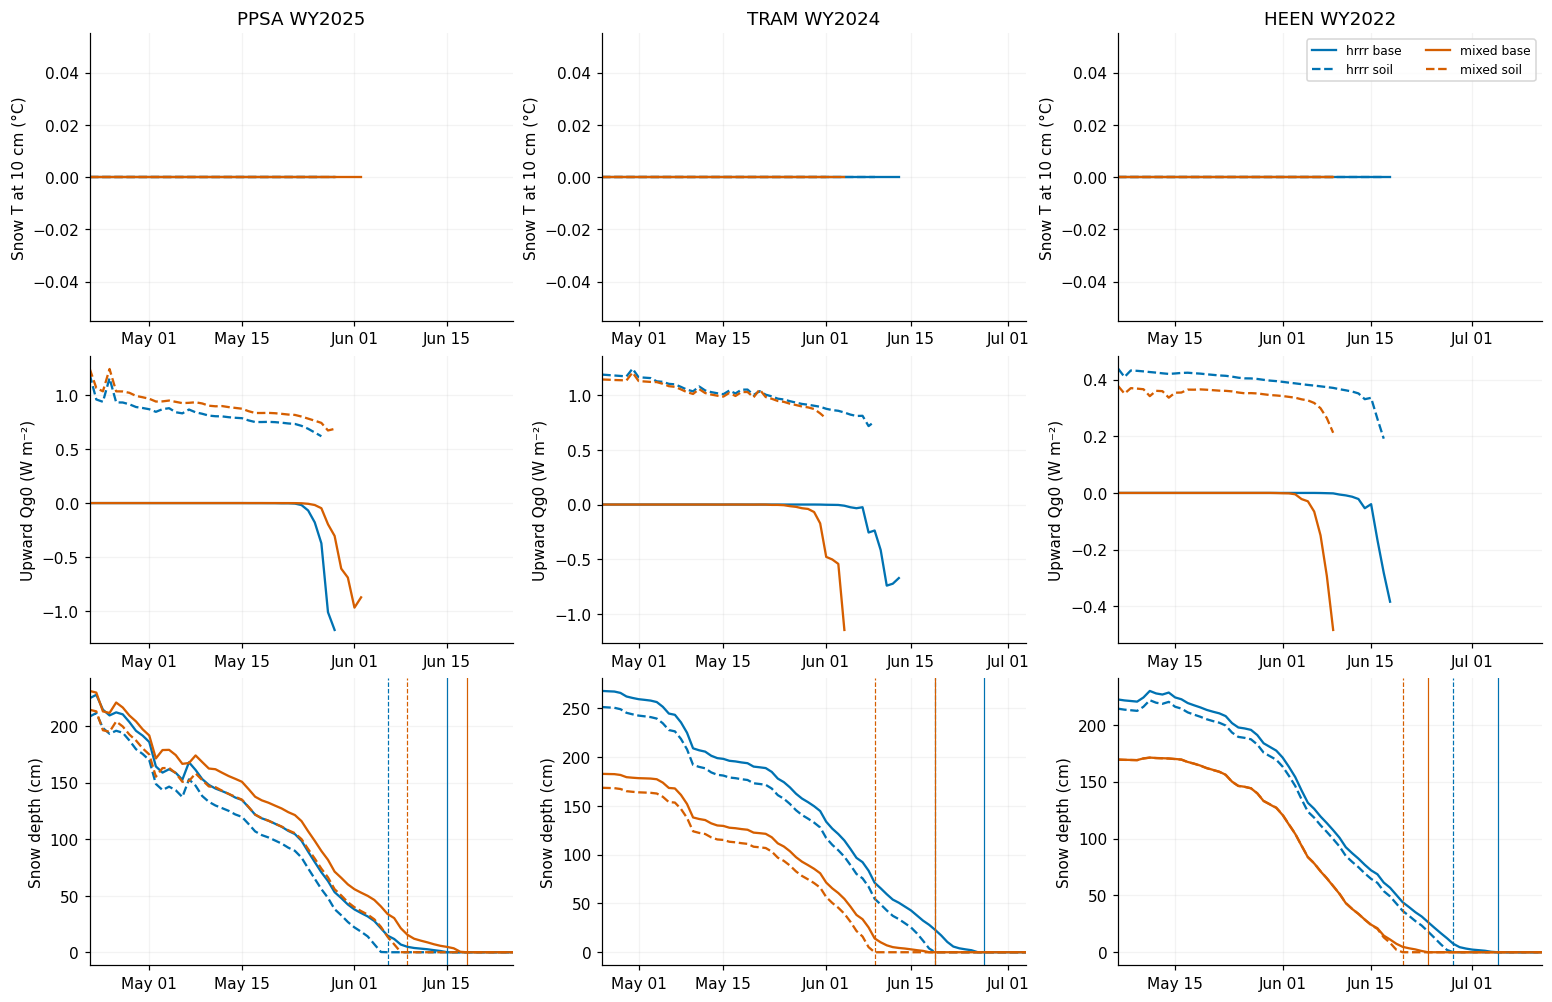

,site,forcing,winter_n,winter_delta_T10_C,winter_delta_bulk_C,winter_delta_cold_deficit_MJm2,spring_n,spring_delta_T10_C,spring_delta_bulk_C,winter_eligible_days_median,winter_snow_coverage_median
0,ppsa,hrrr,5,-0.001,-0.041,-0.010,5,0.000,-0.015,90.0,1.000
1,ppsa,mixed,5,-0.001,-0.075,0.000,5,0.000,-0.018,90.0,1.000
2,tram,hrrr,5,0.000,-0.043,-0.006,5,0.000,-0.011,90.0,1.000
3,tram,mixed,2,-0.201,-0.151,-0.016,2,0.000,-0.022,52.5,0.578
4,heen,hrrr,5,-0.094,-0.116,-0.035,5,-0.039,-0.040,77.0,0.846
5,heen,mixed,2,-0.039,-0.038,0.008,2,-0.009,-0.006,82.5,0.917


- Winter 10 cm temperature changes span -0.201–0.000°C across site/forcing medians; bulk changes span -0.151–-0.038°C.
- Spring 10 cm changes span -0.039–0.000°C, conditioned on simultaneous substantial snow cover.
- The largest retained individual winter cooling at 10 cm is -1.02°C; the full table reports eligible days and snow coverage. Conditional snow-covered means are not necessarily whole-calendar-winter means.
- Interpret profiles and bulk means together: a localized basal effect need not imply comparable warming throughout the snowpack. Near-isothermal melting snow has little temperature range even when energy transfer changes.
- These results include boundary and snow-geometry changes under an assumed soil profile. They cannot validate actual internal snow temperature or uniquely attribute differences to a single energy pathway.

Outputs: /home/cassie/python/repos/snow_modeling_point/figures/internal_snow_temperature


In [5]:
fig,axs=plt.subplots(3,3,figsize=(14,9),layout='constrained')
for c,site in enumerate(SITE_CONFIG):
    wy=selected[site];m=seasons.query('site==@site and water_year==@wy and period=="winter"')
    left=min(m.melt_base.min(),m.melt_soil.min())-pd.Timedelta(days=45);right=max(m.melt_base.max(),m.melt_soil.max())+pd.Timedelta(days=7)
    for f in FORCINGS:
        for exp,ls in [('base','-'),('soil','--')]:
            a=runs[site,f,exp].loc[left:right];snow=a.HS_cm>=50
            temp=a.T_above_10cm_C.where(snow);temp=temp.resample('D').mean().where(temp.resample('D').count()>=18)
            axs[0,c].plot(temp.index,temp,color=COLORS[f],ls=ls,label=f'{f} {exp}')
            q=a.Qg0.where(a.HS_cm>=50);q=q.resample('D').mean().where(q.resample('D').count()>=18)
            axs[1,c].plot(q.index,q,color=COLORS[f],ls=ls)
            hs=a.HS_cm.resample('D').mean();axs[2,c].plot(hs.index,hs,color=COLORS[f],ls=ls)
            date=m.loc[m.forcing==f,'melt_'+exp].iloc[0]
            if pd.notna(date):axs[2,c].axvline(date,color=COLORS[f],ls=ls,lw=.8)
    axs[0,c].set_title(f'{site.upper()} WY{wy}')
    for r,label in enumerate(['Snow T at 10 cm (°C)','Upward Qg0 (W m⁻²)','Snow depth (cm)']):
        axs[r,c].set(ylabel=label,xlim=(left,right));axs[r,c].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3,maxticks=4));axs[r,c].xaxis.set_major_formatter(mdates.DateFormatter('%b %d'));axs[r,c].grid(alpha=.15)
axs[0,-1].legend(fontsize=8,ncol=2);plt.show()
summary=[]
for (site,f),a in seasons.loc[~seasons.first_season].groupby(['site','forcing'],sort=False):
    w=a[a.period=='winter'];s=a[a.period=='spring']
    summary.append(dict(site=site,forcing=f,winter_n=int(w.delta_T_above_10cm_C.notna().sum()),winter_delta_T10_C=w.delta_T_above_10cm_C.median(),
        winter_delta_bulk_C=w.delta_bulk_mass_T_C.median(),winter_delta_cold_deficit_MJm2=w.delta_cold_deficit_MJm2.median(),
        spring_n=int(s.delta_T_above_10cm_C.notna().sum()),spring_delta_T10_C=s.delta_T_above_10cm_C.median(),spring_delta_bulk_C=s.delta_bulk_mass_T_C.median(),
        winter_eligible_days_median=w.eligible_days.median(),winter_snow_coverage_median=w.winter_snow_coverage.median()))
summary=pd.DataFrame(summary);csv(summary,'meeting_summary');display(summary.round(3))
small=summary[['site','forcing','winter_n','winter_delta_T10_C','winter_delta_bulk_C','spring_n','spring_delta_T10_C','spring_delta_bulk_C']].round(3)
text='| '+' | '.join(small.columns)+' |\n| '+' | '.join(['---']*len(small.columns))+' |\n'+'\n'.join('| '+' | '.join(map(str,row))+' |' for row in small.itertuples(index=False,name=None))
messages=[f'Winter 10 cm temperature changes span {summary.winter_delta_T10_C.min():.3f}–{summary.winter_delta_T10_C.max():.3f}°C across site/forcing medians; bulk changes span {summary.winter_delta_bulk_C.min():.3f}–{summary.winter_delta_bulk_C.max():.3f}°C.',
    f'Spring 10 cm changes span {summary.spring_delta_T10_C.min():.3f}–{summary.spring_delta_T10_C.max():.3f}°C, conditioned on simultaneous substantial snow cover.',
    f'The largest retained individual winter cooling at 10 cm is {seasons.loc[(~seasons.first_season)&seasons.period.eq("winter"),"delta_T_above_10cm_C"].min():.2f}°C; the full table reports eligible days and snow coverage. Conditional snow-covered means are not necessarily whole-calendar-winter means.',
    'Interpret profiles and bulk means together: a localized basal effect need not imply comparable warming throughout the snowpack. Near-isothermal melting snow has little temperature range even when energy transfer changes.',
    'These results include boundary and snow-geometry changes under an assumed soil profile. They cannot validate actual internal snow temperature or uniquely attribute differences to a single energy pathway.']
display(Markdown('\n'.join('- '+v for v in messages)))
(OUT/'meeting_summary.md').write_text('# Soil-model impact on internal snow temperatures\n\n'+text+'\n\n'+'\n'.join('- '+v for v in messages)+'\n')
print('Outputs:',OUT)
